# 03 · Linear models, regularisation and the first extension result

**Goal for week 3:** replicate the paper's linear models, show why regularisation is needed with these features, and start the extension: *how well does a model trained on batches 1–2 transfer to a new batch, and how many new-batch cells does it need to recover?*

| Section | Question |
|---|---|
| 1–3 | Baseline → paper's one-feature model → all 12 features (OLS) |
| 4 | Ridge, lasso, elastic net tuned by grouped CV |
| 5 | Why regularisation: twin-feature weights, bootstrapped |
| 6 | Is `charge_time_2to6` helping or just labelling the policy? |
| 7 | Results table (`results/metrics.csv`) and the best model's errors |
| 8 | **Extension:** leave-one-batch-out |
| 9 | **Extension:** k-shot adaptation to batch 3 |

**Rules carried over from weeks 1–2:**
- the target is log₁₀ cycle life, and errors are % in cycles;
- every model uses `StandardScaler` (the Ch 4 drills showed lasso's choices change with units otherwise);
- cross-validation is grouped by charge policy;
- the model is **chosen by CV**, and the test sets are only scored, never used to choose.

*Reading: Hands-On ML Ch 4 (done in the drills).*

In [2]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import ElasticNet, Lasso, LinearRegression, Ridge
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.features import FEATURE_COLUMNS, load_feature_table
from src.evaluate import (cv_log_mae, evaluate, grouped_cv, pct_error,
                          save_metrics, signed_pct)

FIGURES = ROOT / "results" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
METRICS_CSV = ROOT / "results" / "metrics.csv"
SEED = 42

data = load_feature_table(ROOT / "data" / "processed" / "features.csv")
y = np.log10(data["cycle_life"])
train = data[data["split"] == "train"]
X_tr, y_tr, groups_tr = train[FEATURE_COLUMNS], np.log10(train["cycle_life"]), train["charge_policy"]
print(data["split"].value_counts().to_dict())

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})


def pipe(model):
    """Impute (median), scale, then model — the standard pipeline for every linear model."""
    return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), model)


rows = []  # one metrics row per model, saved to results/metrics.csv in section 7

{'test': 43, 'train': 41, 'secondary_test': 40}


## 1 · Baseline: predict the training average for every cell

Any model worth having must beat this. It also tells you how much of the error comes from the spread in lifetimes alone.

In [3]:
row, _ = evaluate("Baseline (train mean)", pipe(DummyRegressor()), data, FEATURE_COLUMNS)
rows.append(row)
pd.Series(row).to_frame("value")

,value
model,Baseline (train mean)
n_features,12
note,
cv_log_mae,0.135928
cv_log_mae_std,0.03382
train_pct,29.629703
test_pct,34.997955
secondary_test_pct,36.053894
b1_bias_pct,-24.943677
b2_bias_pct,41.582754


## 2 · The paper's "variance model": one feature

Linear regression on `log_var_dq` alone. Look up the paper's error for its variance model (Table 1) and compare.

In [4]:
row, var_model = evaluate("Variance model (1 feature)", pipe(LinearRegression()), data, ["log_var_dq"])
rows.append(row)
pd.Series(row).to_frame("value")

,value
model,Variance model (1 feature)
n_features,1
note,
cv_log_mae,0.06458
cv_log_mae_std,0.004045
train_pct,14.124443
test_pct,14.747106
secondary_test_pct,11.415496
b1_bias_pct,-8.118844
b2_bias_pct,17.502076


*Notes:*

Baseline (predict training mean): test 35.0%, secondary 36.1%, the error from lifetime spread alone; batch biases b1 −25%, b2 +42%, b3 −35% reflect each batch’s average life relative to training. Variance model (log_var_dq only): test 14.7%, secondary 11.4%, more than halving the error with one feature.

Variance model (log_var_dq only): train 14.1%, test 14.7%, secondary 11.4%, matching the paper’s Table 1 exactly (14.1 / 14.7 / 11.4). This confirms the full pipeline (loading, cell cleaning, splicing, cycle indexing, ΔQ feature) reproduces the authors’ work, so later improvements and extension results can be trusted as real effects rather than setup differences.

Possible differences: feature details (cycle indices, voltage grid, interpolation), cell cleaning/splicing, error metric definition, fitting method. Notably, b3 bias is only −0.8% (vs about −11% for the 12-feature OLS in week 2), suggesting the batch 3 shift enters through the other features (IR, capacity, charge time), not ΔQ. Batch 2 still over-predicted (+17.5%): aggressive policies not captured by one feature.

## 3 · All 12 features, ordinary least squares (OLS)

The Chapter 2 drills got 15.2% test and 15.3% secondary with this. The gap between training error and test error tells you about overfitting.

In [5]:
row, ols = evaluate("OLS (12 features)", pipe(LinearRegression()), data, FEATURE_COLUMNS)
rows.append(row)
pd.Series(row).to_frame("value")

,value
model,OLS (12 features)
n_features,12
note,
cv_log_mae,0.044789
cv_log_mae_std,0.012622
train_pct,6.214965
test_pct,15.175731
secondary_test_pct,15.333884
b1_bias_pct,-0.303467
b2_bias_pct,9.202576


## 4 · Regularised models, tuned by grouped cross-validation

Each model's strength (α, and for elastic net the lasso/ridge mix `l1_ratio`) is chosen by 5-fold CV on the 41 training cells, grouped by charge policy. The test sets play no part in the choice.

In [6]:
cv = grouped_cv(5)
searches = {
    "Ridge": (Ridge(), {"ridge__alpha": np.logspace(-3, 3, 31)}),
    "Lasso": (Lasso(max_iter=50_000), {"lasso__alpha": np.logspace(-4, 0, 41)}),
    "Elastic net": (ElasticNet(max_iter=50_000),
                    {"elasticnet__alpha": np.logspace(-4, 0, 21),
                     "elasticnet__l1_ratio": [0.1, 0.3, 0.5, 0.7, 0.9]}),
}

tuned = {}
for name, (model, grid) in searches.items():
    search = GridSearchCV(pipe(model), grid, cv=cv, scoring="neg_mean_absolute_error")
    search.fit(X_tr, y_tr, groups=groups_tr)
    tuned[name] = search
    best = {k.split("__")[1]: float(np.round(v, 4)) for k, v in search.best_params_.items()}
    row, _ = evaluate(name, search.best_estimator_, data, FEATURE_COLUMNS, note=str(best))
    rows.append(row)
    print(f"{name:12s} best {best}  CV log-MAE {-search.best_score_:.4f}")

Ridge        best {'alpha': 0.631}  CV log-MAE 0.0435
Lasso        best {'alpha': 0.005}  CV log-MAE 0.0405
Elastic net  best {'alpha': 0.0063, 'l1_ratio': 0.7}  CV log-MAE 0.0404


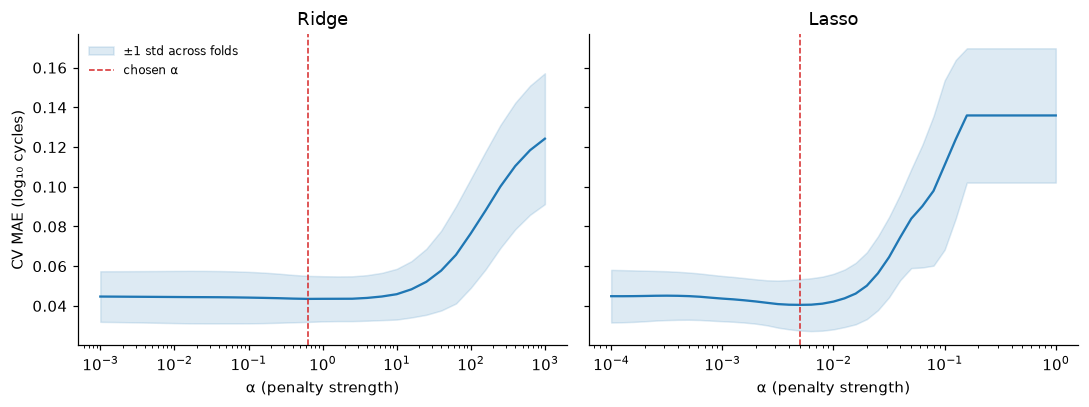

In [7]:
# How CV error changes with the penalty strength (ridge and lasso)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
for ax, name in zip(axes, ["Ridge", "Lasso"]):
    res = pd.DataFrame(tuned[name].cv_results_)
    alpha = res[f"param_{name.lower()}__alpha"].astype(float)
    mean, std = -res["mean_test_score"], res["std_test_score"]
    ax.plot(alpha, mean, color="C0")
    ax.fill_between(alpha, mean - std, mean + std, color="C0", alpha=0.15, label="±1 std across folds")
    ax.axvline(tuned[name].best_params_[f"{name.lower()}__alpha"], color="C3", ls="--", lw=1, label="chosen α")
    ax.set_xscale("log"); ax.set_xlabel("α (penalty strength)"); ax.set_title(name)
axes[0].set_ylabel("CV MAE (log₁₀ cycles)")
axes[0].legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(FIGURES / "03_cv_vs_alpha.png", dpi=200)

*Notes:*

CV error is flat for α below ~10¹ (ridge) and ~10⁻² (lasso). In that region the penalty is negligible and both behave like OLS (CV MAE ≈ 0.045). Above the threshold the penalty dominates and the models underfit; lasso plateaus at ≈ 0.136, equal to the baseline CV error, because it has zeroed every coefficient and predicts the training mean. The chosen α's dip (lasso ≈ 0.041 vs 0.045) is small compared with the ±~0.012 fold-to-fold band, so CV can’t clearly separate it from no penalty; α only needs to be in the right order of magnitude. The larger test-set gain from the drills (15.2% → 11.6%) should be checked here and treated cautiously given 43 test cells.

log_var_dq             0.1314
ir_min                 0.0441
charge_time_2to6       0.0441
qd_cycle2              0.0377
log_abs_min_dq         0.0068
temp_max               0.0058
qd_max_minus_cycle2    0.0050
log_abs_skew_dq        0.0023
ir_change_2to100       0.0019
log_abs_kurt_dq        0.0017
fade_slope             0.0008
fade_intercept         0.0001
Name: largest α still non-zero, dtype: float64

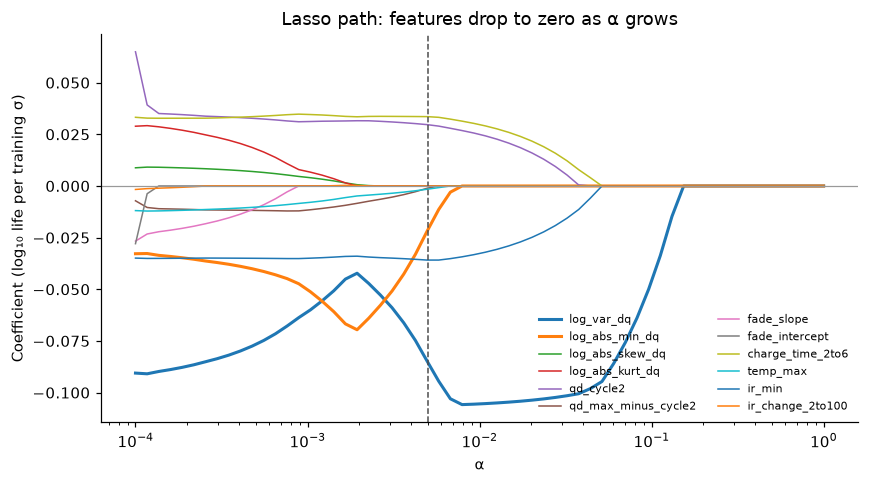

In [8]:
# Lasso path: which features survive as the penalty grows
alphas = np.logspace(-4, 0, 60)
path = pd.DataFrame(
    [pipe(Lasso(alpha=a, max_iter=50_000)).fit(X_tr, y_tr)[-1].coef_ for a in alphas],
    index=alphas, columns=FEATURE_COLUMNS)

fig, ax = plt.subplots(figsize=(8, 4.5))
for feat in FEATURE_COLUMNS:
    lw = 2 if feat in ("log_var_dq", "log_abs_min_dq") else 1
    ax.plot(path.index, path[feat], lw=lw, label=feat)
ax.axvline(tuned["Lasso"].best_params_["lasso__alpha"], color="0.3", ls="--", lw=1)
ax.axhline(0, color="0.6", lw=0.8)
ax.set_xscale("log"); ax.set_xlabel("α"); ax.set_ylabel("Coefficient (log₁₀ life per training σ)")
ax.set_title("Lasso path: features drop to zero as α grows")
ax.legend(fontsize=7, ncol=2, frameon=False, loc="lower right")
fig.tight_layout()
fig.savefig(FIGURES / "03_lasso_path.png", dpi=200)

survives_to = {f: path.index[path[f] != 0].max() if (path[f] != 0).any() else 0.0 for f in FEATURE_COLUMNS}
pd.Series(survives_to, name="largest α still non-zero").sort_values(ascending=False).round(4)

*Notes:*

log_var_dq survives longest (to α ≈ 0.15), matching the paper’s choice of it for the single-feature model. Next to go are ir_min (≈0.1), then charge_time_2to6 and qd_cycle2 (≈0.05); everything else is zero by ≈0.01. The twins log_var_dq and log_abs_min_dq trade weight at small α. Once lasso zeroes log_abs_min_dq (~6×10⁻³), log_var_dq’s coefficient jumps from ≈ −0.04 to ≈ −0.105 as it absorbs the shared signal, so lasso keeps one of a correlated pair rather than splitting the weight. The negative sign is physical: more uneven capacity loss across voltage means shorter life. Surviving longest shows predictive strength in this dataset, not causation.

## 5 · Why regularisation: the twin features, bootstrapped

Week 2 found two near-duplicate pairs (r ≈ 1). Here the training cells are resampled 200 times and each model refitted. If a coefficient swings wildly between resamples, the model can't decide how to split weight between twins, so the individual weights mean nothing physically.

,OLS coef std,Ridge coef std
log_var_dq,0.147,0.017
log_abs_min_dq,0.140,0.015
qd_cycle2,0.265,0.008
fade_intercept,0.251,0.008


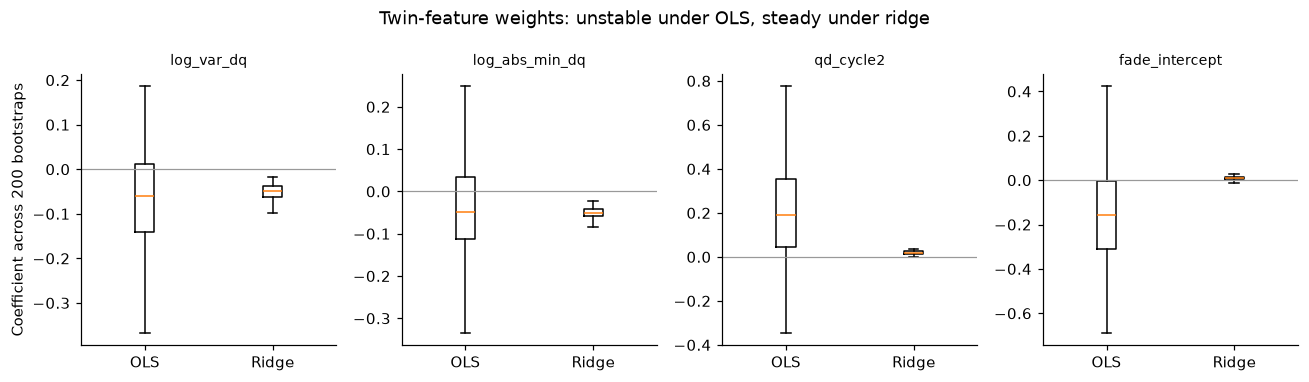

In [9]:
twins = ["log_var_dq", "log_abs_min_dq", "qd_cycle2", "fade_intercept"]
ridge_best = tuned["Ridge"].best_estimator_
rng = np.random.default_rng(SEED)
boot = {"OLS": [], "Ridge": []}
for _ in range(200):
    idx = rng.choice(len(X_tr), size=len(X_tr), replace=True)
    Xb, yb = X_tr.iloc[idx], y_tr.iloc[idx]
    boot["OLS"].append(pipe(LinearRegression()).fit(Xb, yb)[-1].coef_)
    boot["Ridge"].append(pipe(Ridge(alpha=ridge_best[-1].alpha)).fit(Xb, yb)[-1].coef_)

fig, axes = plt.subplots(1, 4, figsize=(12, 3.5))
for ax, feat in zip(axes, twins):
    j = FEATURE_COLUMNS.index(feat)
    ax.boxplot([np.array(boot["OLS"])[:, j], np.array(boot["Ridge"])[:, j]],
               tick_labels=["OLS", "Ridge"], showfliers=False)
    ax.axhline(0, color="0.6", lw=0.8)
    ax.set_title(feat, fontsize=9)
axes[0].set_ylabel("Coefficient across 200 bootstraps")
fig.suptitle("Twin-feature weights: unstable under OLS, steady under ridge")
fig.tight_layout()
fig.savefig(FIGURES / "03_twin_bootstrap.png", dpi=200)

pd.DataFrame({m: pd.DataFrame(v, columns=FEATURE_COLUMNS)[twins].std() for m, v in boot.items()}).round(3).rename(
    columns=lambda c: f"{c} coef std")

*Notes:*

Ridge cuts the coefficient spread ~9× for the ΔQ twins and ~30× for the capacity twins. It penalises the sum of squared weights, so for near-identical features it shares the weight evenly rather than letting the two fight. OLS can give qd_cycle2 and fade_intercept large opposite weights (+0.19 / −0.15) without hurting training error because, with r = 0.99, the prediction depends only on the sum of the two weights. The difference multiplies a near-zero noise term, so OLS sets it to fit noise and it swings between resamples. The sums agree across models (capacity ≈ +0.04 OLS vs +0.03 ridge; ΔQ ≈ −0.11 vs −0.10, and lasso’s single log_var_dq ≈ −0.105). The models agree on the combined effect and differ only in the split. The risk is at test time: if a new cell’s twins differ slightly (e.g. batch shift), OLS’s opposite weights amplify it.

## 6 · Is `charge_time_2to6` helping, or just labelling the policy?

Week 2 argued this feature mostly encodes the charging policy, and that batch 3's cells all share roughly the same charge time. If so, dropping it should hurt the primary test (shared policies) more than the secondary test.

In [10]:
best_name = min(tuned, key=lambda n: -tuned[n].best_score_)
print("Best regularised model by CV:", best_name)
no_ct = [f for f in FEATURE_COLUMNS if f != "charge_time_2to6"]

search = GridSearchCV(pipe(searches[best_name][0]), searches[best_name][1], cv=cv,
                      scoring="neg_mean_absolute_error").fit(train[no_ct], y_tr, groups=groups_tr)
row, _ = evaluate(f"{best_name} without charge_time", search.best_estimator_, data, no_ct)
rows.append(row)

compare = pd.DataFrame([r for r in rows if r["model"] in (best_name, f"{best_name} without charge_time")]).set_index("model")
compare[["cv_log_mae", "test_pct", "secondary_test_pct", "b3_bias_pct"]].round(3)

Best regularised model by CV: Elastic net


,cv_log_mae,test_pct,secondary_test_pct,b3_bias_pct
model,,,,
Elastic net,0.040,11.569,12.486,-7.440
Elastic net without charge_time,0.048,11.476,13.403,7.676


*Notes:*

Removing charge_time_2to6: the primary test is unchanged (11.57 → 11.48%, within the ~0.5-point noise), the secondary test is slightly worse (12.49 → 13.40%), and grouped CV is worse (0.040 → 0.048). This is the opposite of the “disguised label” prediction. The primary test cells share policies with training, so the policy information can be recovered from correlated features (temp_max, ΔQ shape). Grouped CV holds out whole policies, where a pure label couldn’t help, so the CV loss suggests charge time carries transferable physics (faster charge, shorter life). Conclusion: it’s a real but policy-linked feature, not just a label. However, it drives the batch 3 bias: −7.4% with it vs +7.7% without, a ~15% swing. Batch 3’s shared charge time maps to a shorter predicted life than observed, making it the most batch-sensitive feature. Revisit in leave-one-batch-out.

## 7 · Results table and the best model's errors

In [11]:
table = save_metrics(rows, METRICS_CSV)
cols = ["n_features", "cv_log_mae", "cv_log_mae_std", "train_pct", "test_pct",
        "secondary_test_pct", "b1_bias_pct", "b2_bias_pct", "b3_bias_pct", "note"]
table[cols].round(3)

,n_features,cv_log_mae,cv_log_mae_std,train_pct,test_pct,secondary_test_pct,b1_bias_pct,b2_bias_pct,b3_bias_pct,note
model,,,,,,,,,,
Baseline (train mean),12,0.136,0.034,29.630,34.998,36.054,-24.944,41.583,-35.303,
Variance model (1 feature),1,0.065,0.004,14.124,14.747,11.415,-8.119,17.502,-0.778,
OLS (12 features),12,0.045,0.013,6.215,15.176,15.334,-0.303,9.203,-11.241,
Ridge,12,0.044,0.012,6.519,12.099,13.637,-1.526,4.578,-8.062,{'alpha': 0.631}
Lasso,12,0.041,0.013,7.366,11.612,12.725,-3.488,8.614,-7.651,{'alpha': 0.005}
Elastic net,12,0.040,0.013,7.246,11.569,12.486,-3.214,8.224,-7.440,"{'alpha': 0.0063, 'l1_ratio': 0.7}"
Elastic net without charge_time,11,0.048,0.013,7.938,11.476,13.403,-4.144,9.319,7.676,


,split,charge_policy,cycle_life,pred_life,err_pct
cell,,,,,
b2c1,test,2C(10%)-6C,148.0,328.2,121.8
b3c38,secondary_test,5C(67%)-4C-newstructure,1935.0,1018.4,-47.4
b3c7,secondary_test,4.8C(80%)-4.8C-newstructure,1836.0,1286.1,-29.9
b2c36,test,5.6C(25%)-4.5C,535.0,378.7,-29.2
b3c45,secondary_test,4.8C(80%)-4.8C-newstructure,1801.0,1304.9,-27.5
b3c41,secondary_test,5.6C(36%)-4.3C-newstructure,786.0,578.1,-26.4
b1c2,test,3.6C(80%)-3.6C,2237.0,1685.2,-24.7
b3c22,secondary_test,5.9C(60%)-3.1C-newstructure,1002.0,755.0,-24.6


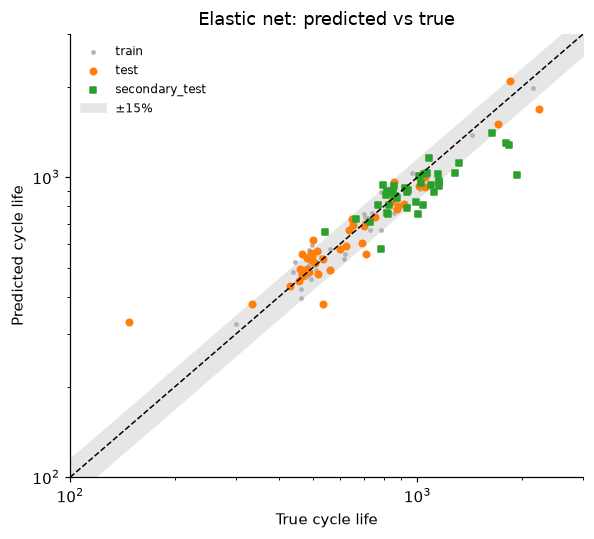

In [12]:
best = tuned[best_name].best_estimator_
pred = pd.Series(best.predict(data[FEATURE_COLUMNS]), index=data.index)

fig, ax = plt.subplots(figsize=(5.5, 5))
for split, colour, marker in [("train", "0.7", "."), ("test", "C1", "o"), ("secondary_test", "C2", "s")]:
    m = data["split"] == split
    ax.scatter(data.loc[m, "cycle_life"], 10 ** pred[m], s=18, color=colour, marker=marker, label=split)
lims = [100, 3000]
ax.plot(lims, lims, "k--", lw=1)
ax.fill_between(lims, [l * 0.85 for l in lims], [l * 1.15 for l in lims], color="0.9", zorder=0, label="±15%")
ax.set(xscale="log", yscale="log", xlim=lims, ylim=lims, xlabel="True cycle life",
       ylabel="Predicted cycle life", title=f"{best_name}: predicted vs true")
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(FIGURES / "03_pred_vs_true.png", dpi=200)

worst = data.assign(pred_life=10 ** pred, err_pct=signed_pct(y, pred))
worst = worst[worst["split"] != "train"]
worst.reindex(worst["err_pct"].abs().sort_values(ascending=False).index)[
    ["split", "charge_policy", "cycle_life", "pred_life", "err_pct"]].head(8).round(1)

In [13]:
var_fit = make_pipeline(LinearRegression()).fit(train[["log_var_dq"]], y_tr)
p = pd.Series(var_fit.predict(data[["log_var_dq"]]), index=data.index)
y = np.log10(data["cycle_life"])
t = data["split"] == "test"
err = pd.Series(pct_error(y[t], p[t]), index=data.index[t])
print("b2c1 error:", err["b2c1"].round(1))
print("test mean without b2c1:", err.drop("b2c1").mean().round(1))

b2c1 error: 80.0
test mean without b2c1: 13.2


*Notes:*

Model choice. Chosen by CV, not test: elastic net (α = 0.0063, l1_ratio = 0.7) with CV MAE 0.040, test 11.6%, secondary 12.5%. Ridge, lasso and EN are tied within noise (CV 0.040–0.044, std ≈ 0.012; test within 0.5 points). The no-charge_time variant’s 11.48% test is noise and isn’t grounds to pick it; its CV and secondary errors are worse.

Regularisation. OLS overfits: 6.2% train vs 15.2% test (~9-point gap). Regularised models cut the gap to ~4–5 points (train 6.5–7.4%, test 11.6–12.1%).

Batch bias. Every 12-feature model over-predicts b2 (+5 to +9%) and under-predicts b3 (−7 to −11%); b1 is near zero. The variance model has almost no b3 bias (−0.8%) but +17.5% on b2. So the b3 shift comes in through the extra features, not log_var_dq.

Worst cell: b2c1 (2C(10%)-6C, 148 cycles, predicted 328, +122%). It is far shorter-lived than any training cell, so the model would have to extrapolate. It alone adds ~2.7 points to the test mean (≈ 8.9% without it). It is the cell the paper excludes in Table 1’s parentheses (“reaches 80% SOH rapidly”). Confirmed: our variance model gives 80.0% error on b2c1 and 13.2% test without it, exactly matching the paper’s 14.7 (13.2).

Comparison with the paper (primary test with / without b2c1; secondary):

Paper discharge: 13.0 / 10.1; 8.6
Paper full: 14.1 / 7.5; 10.7
Our elastic net: 11.6 / ≈ 8.9; 12.5

Ours is more robust to the outlier (122% vs ≈ 290% error for the paper’s full model, back-calculated from Table 1). It is slightly less sharp on typical cells and worse on batch 3. This is the regularisation trade-off: shrunk weights give less extreme predictions.

Other worst cells. All are under-predicted long-lived cells, 5 of 7 from b3 “newstructure” (e.g. b3c38: 1935 cycles, predicted 1018). Predictions are compressed towards the middle at both extremes: the shortest cell is over-predicted and the longest are under-predicted. Causes: regularisation shrinkage plus the b3 domain shift.

For the objective. A stop rule can’t exclude cells after the fact, and a rapidly failing cell is the one most worth catching. Week 4 test: does a prediction interval flag b2c1 (and the long-lived b3 cells) as uncertain, rather than giving a confident wrong answer?

## 8 · Extension: leave-one-batch-out

The paper's split mixes batches 1 and 2 in training and holds out batch 3. Here each batch takes a turn as the held-out set: train on **all** cells from the other two batches (α re-tuned inside them by grouped CV), then test on every cell of the held-out batch.

This answers: *is batch 3 unusually hard, or does every new batch shift?*

In [14]:
model, grid = searches[best_name]
lobo = []
for held_out in ["b1", "b2", "b3"]:
    tr_m = data["batch"] != held_out
    s = GridSearchCV(pipe(model), grid, cv=cv, scoring="neg_mean_absolute_error")
    s.fit(data.loc[tr_m, FEATURE_COLUMNS], y[tr_m], groups=data.loc[tr_m, "charge_policy"])
    p = s.predict(data.loc[~tr_m, FEATURE_COLUMNS])
    lobo.append({"held_out": held_out, "n_train": int(tr_m.sum()), "n_test": int((~tr_m).sum()),
                 "abs_err_pct": pct_error(y[~tr_m], p).mean(),
                 "signed_bias_pct": signed_pct(y[~tr_m], p).mean()})
pd.DataFrame(lobo).set_index("held_out").round(1)

,n_train,n_test,abs_err_pct,signed_bias_pct
held_out,,,,
b1,83,41,13.7,-11.2
b2,81,43,24.1,23.7
b3,84,40,11.3,-5.5


*Notes:*

Hardest batch to hold out: b2 (24.1% error, +23.7% bias). Almost all of the error is a systematic over-prediction, not scatter. b1: 13.7% (−11.2%); b3: 11.3% (−5.5%). Batch 3 isn’t unusually hard: with all b1+b2 cells in training it beats the paper-split secondary result (12.5%, −7.4%). The bias direction differs between batches (−11, +24, −6), so every new batch shifts by an unpredictable amount and sign, and a fixed correction won’t work. Grouped CV (by policy, ~10% error) doesn’t capture this, because every fold mixes batches; leave-one-batch-out is the honest estimate for next year’s cells. Implication for the stop rule: expect ±5–25% bias on a new batch unless the model is recalibrated with a few cells from that batch → section 9 (k-shot). b2 is also over-predicted (+5–9%) in section 7; b2c1 explains only ~3 points of it.

## 9 · Extension: how many new-batch cells does the model need?

Start from the paper's training set (41 cells from batches 1–2). Move **k** randomly chosen batch 3 cells into training, refit, and test on the **remaining** batch 3 cells. Repeat 50 times per k with different random picks, because which cells you pick matters a lot with so few.

This is the practical question for a test lab: *when a new cell lot arrives, how many cells must be cycled to end of life before early predictions for the rest can be trusted?*

(α is kept at the CV-chosen value from section 4, so only the training data changes. This experiment uses batch 3 cells for training, so its numbers are separate from the headline secondary-test error, which is the k = 0 case.)

In [15]:
b3 = data.index[data["split"] == "secondary_test"].to_numpy()
fixed = tuned[best_name].best_estimator_
rng = np.random.default_rng(SEED)
ks, n_rep = [0, 2, 5, 10, 15, 20], 50
records = []
for k in ks:
    for rep in range(1 if k == 0 else n_rep):
        added = rng.choice(b3, size=k, replace=False) if k else np.array([], dtype=b3.dtype)
        rest = np.setdiff1d(b3, added)
        tr_idx = np.concatenate([train.index.to_numpy(), added])
        fit = clone(fixed).fit(data.loc[tr_idx, FEATURE_COLUMNS], y[tr_idx])
        p = fit.predict(data.loc[rest, FEATURE_COLUMNS])
        records.append({"k": k, "rep": rep, "abs_err_pct": pct_error(y[rest], p).mean(),
                        "bias_pct": signed_pct(y[rest], p).mean()})
kshot = pd.DataFrame(records)
summary = kshot.groupby("k")[["abs_err_pct", "bias_pct"]].agg(["median", lambda s: s.quantile(0.25),
                                                                 lambda s: s.quantile(0.75)])
summary.columns = [f"{a}_{b}" for a, b in zip(summary.columns.get_level_values(0),
                                              ["median", "q25", "q75"] * 2)]
summary.round(1)

,abs_err_pct_median,abs_err_pct_q25,abs_err_pct_q75,bias_pct_median,bias_pct_q25,bias_pct_q75
k,,,,,,
0,12.5,12.5,12.5,-7.4,-7.4,-7.4
2,12.0,11.6,12.5,-1.7,-5.5,1.7
5,11.1,10.5,12.5,-2.2,-6.0,1.1
10,10.5,9.7,11.3,-0.3,-3.1,3.0
15,9.9,8.7,10.7,-0.2,-3.0,2.3
20,9.5,8.3,10.1,-0.3,-3.0,2.3


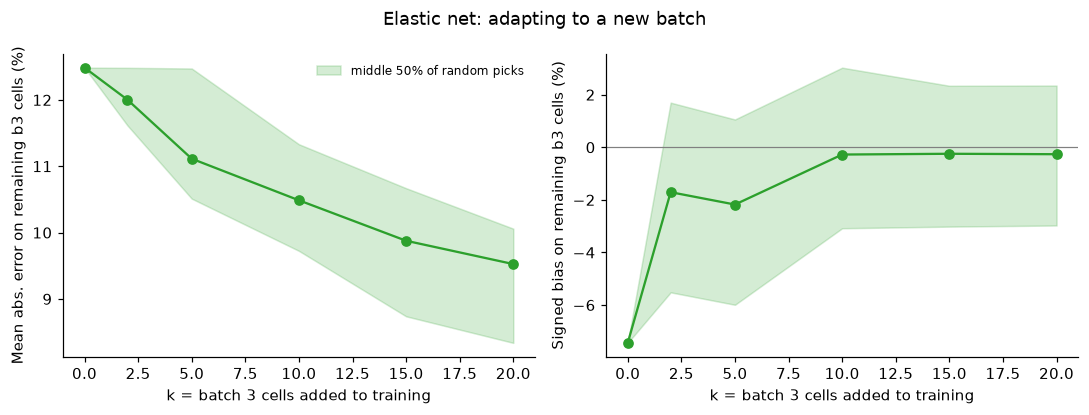

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for ax, col, label in [(axes[0], "abs_err_pct", "Mean abs. error on remaining b3 cells (%)"),
                       (axes[1], "bias_pct", "Signed bias on remaining b3 cells (%)")]:
    ax.plot(summary.index, summary[f"{col}_median"], marker="o", color="C2")
    ax.fill_between(summary.index, summary[f"{col}_q25"], summary[f"{col}_q75"], color="C2", alpha=0.2,
                    label="middle 50% of random picks")
    ax.set_xlabel("k = batch 3 cells added to training"); ax.set_ylabel(label)
axes[1].axhline(0, color="0.5", lw=0.8)
axes[0].legend(frameon=False, fontsize=8)
fig.suptitle(f"{best_name}: adapting to a new batch")
fig.tight_layout()
fig.savefig(FIGURES / "03_kshot_batch3.png", dpi=200)

*Notes:*

The median bias drops from −7.4% to ~−2% with just 2 batch 3 cells and is ≈0 from k = 10, though individual random picks still vary by ±3%. The error doesn’t plateau: 12.5% → 10.5% (k = 10) → 9.5% (k = 20), still falling. The first cells fix the shift; more cells keep reducing scatter. At k = 5 (11.1%) it already beats training on all 84 b1+b2 cells (11.3% in leave-one-batch-out): a few cells from the new batch beat many from old ones. Recommendation: for a new cell lot, cycle ~10 cells across the test conditions to end of life, add them to training, stop the rest at cycle 100 and predict (expect ≈0 ± 3% bias, ~10.5% error). This saves channel time, not calendar time, as predictions wait for the calibration cells to finish. Caveat: the test set shrinks to 40 − k cells, so high-k points are noisier.

---
## Week 3 findings

*Verified on real data (21 Oct). Drill numbers checked against the notebook; notebook values used where they differ.*

- **Baseline (predict training mean):** test 35.0%, secondary 36.1%: the error from lifetime spread alone. CV MAE 0.136 log10.
- **Variance model (1 feature):** train 14.1%, test 14.7%, secondary 11.4%; the paper reports 14.1 / 14.7 / 11.4%. Exact reproduction, validating the data pipeline. Without b2c1: 13.2% (paper: 13.2%).
- **OLS, 12 features:** train 6.2%, test 15.2%, secondary 15.3%. The ~9-point train–test gap shows overfitting with 41 cells and 12 features.
- **Regularised:** Ridge (α = 0.63) 12.1% / 13.6%; Lasso (α = 0.005) 11.6% / 12.7%; **Elastic net (α = 0.0063, l1_ratio = 0.7) 11.6% / 12.5%, best by CV (0.040)**. All three are tied within noise (CV 0.040–0.044, std ≈ 0.012). The train–test gap narrows to ~4–5 points. The test-set gain over OLS (15.2 → 11.6%) is clear, but CV alone can't separate the tuned α from no penalty: the CV curve is flat below α ≈ 10¹ (ridge) / 10⁻² (lasso), and the dip is inside the fold-to-fold band. α only needs the right order of magnitude.
- **Lasso path:** `log_var_dq` is the last feature standing (to α ≈ 0.15), matching the paper's single-feature choice. Then ir_min (≈ 0.1), charge_time_2to6 and qd_cycle2 (≈ 0.05). When lasso drops its twin `log_abs_min_dq`, `log_var_dq`'s weight jumps from ≈ −0.04 to ≈ −0.105 as it absorbs the shared signal.
- **Twins:** OLS bootstrap coefficient std 0.14–0.15 (ΔQ pair) and 0.25–0.27 (capacity pair) vs ridge 0.015–0.017 and 0.008: ~9× and ~30× tighter. OLS gives opposite-sign weights to near-duplicates (qd_cycle2 +0.19, fade_intercept −0.15) because only their sum affects predictions. The sums agree across OLS, ridge and lasso (ΔQ ≈ −0.10 to −0.11).
- **charge_time_2to6 ablation:** removing it leaves the primary test unchanged (11.6 → 11.5%, noise) but worsens the secondary test (12.5 → 13.4%) and grouped CV (0.040 → 0.048). The opposite of the "disguised label" prediction: it carries transferable charge-rate physics, not just a policy label. It is the most batch-sensitive feature, swinging b3 bias from −7.4% to +7.7%.
- **Worst cells:** b2c1 (148 cycles, predicted 328, +122%) is the paper's excluded cell; it adds ~2.7 points to the test mean (EN ≈ 8.9% without it vs the paper's full model 7.5%). Ours is more robust to it (122% vs ≈ 290% back-calculated for the paper's full model). The other worst cells are under-predicted long-lived cells, 5 of 7 from b3: predictions are compressed towards the middle at both extremes.
- **Batch bias (paper split):** every 12-feature model over-predicts b2 (+5 to +9%) and under-predicts b3 (−7 to −11%); the variance model has little b3 bias (−0.8%) but +17.5% on b2.
- **Learning curves (drills):** 12-feature validation error flattens by ~24 cells; more cells would gain ~1–2 points, so regularise rather than cycle more cells for accuracy. (But see k-shot: cells from the *right batch* are worth far more than more cells overall.)
- **Leave-one-batch-out:** b1 13.7% (bias −11.2%), b2 24.1% (+23.7%), b3 11.3% (−5.5%). Every batch shifts, in different directions, so no fixed correction works. b3 isn't unusually hard; b2 is. Policy-grouped CV (~10%) misses batch shift entirely: leave-one-batch-out is the honest estimate for a new lot.
- **k-shot (extension):** adding batch 3 cells to training removes most of the bias with 2 cells and essentially all of it by 10 (≈ 0 ± 3% across random picks). Error falls 12.5 → 10.5% (k = 10) → 9.5% (k = 20) and hasn't plateaued. At k = 5 (11.1%) it already beats training on all 84 b1+b2 cells. **Lab recommendation:** for a new cell lot, cycle ~10 cells across the test conditions to end of life, recalibrate, and stop the rest at cycle 100. This saves channel time, not calendar time. Caveat: the test set shrinks to 40 − k cells, so high-k points are noisier.

**Carry into week 4:** prediction intervals. Do they flag b2c1 and the long-lived b3 cells as uncertain? Is the batch-level uncertainty (±5–25%) visible in the intervals?